# P4 · Ejemplo resuelto en Python: algoritmo genético y diseño de experimentos con bloques

**Inteligencia Artificial I · UCM · Curso 2026-27 · Prof. Mailyn Moreno Espino**

Este cuaderno es la programación, paso a paso, del documento *«P4 · Ejemplo resuelto»*. Ejecutad las celdas en orden: cada una construye una pieza y la prueba antes de pasar a la siguiente.

1. El problema de los bloques
2. Las piezas del genético, una a una
3. Las dos generaciones a mano (OneMax, n = 16), reproducidas con el código
4. El genético completo con presupuesto de evaluaciones
5. El diseño de experimentos (Deceptive, n = 32): la trampa de las generaciones, fase 1, fase 2 y validación

Solo usa la biblioteca estándar de Python y `matplotlib` para la gráfica final. Con la mochila haréis lo mismo cambiando la función de aptitud y tratando la restricción de capacidad.

## 1. El problema de los bloques

Una solución es una lista de n bits (n múltiplo de 4). Se divide en bloques de 4 bits y cada bloque aporta f(u), donde u es su número de unos. La aptitud total es la suma.

In [ ]:
import random
import statistics
import math
import itertools

# f(u) para u = 0, 1, 2, 3, 4 unos en el bloque
FUNCIONES = {
    "onemax":    [0, 1, 2, 3, 4],
    "plateau":   [0, 0, 0, 3, 4],
    "royal":     [0, 0, 0, 0, 4],
    "deceptive": [3, 2, 1, 0, 4],
}

def aptitud(x, tabla):
    # Suma f(u) sobre los bloques de 4 bits de x.
    return sum(tabla[sum(x[i:i + 4])] for i in range(0, len(x), 4))

# Utilidades para leer y escribir cadenas como en el documento
def bits(cadena):
    return [int(c) for c in cadena if c in "01"]

def texto(x):
    s = "".join(map(str, x))
    return " ".join(s[i:i + 4] for i in range(0, len(s), 4))

x = bits("1011 0000 1111 0100")
for nombre, tabla in FUNCIONES.items():
    print(f"{nombre:10s} F({texto(x)}) = {aptitud(x, tabla)}")

[1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0]
onemax     F(1011 0000 1111 0100) = 8
plateau    F(1011 0000 1111 0100) = 7
royal      F(1011 0000 1111 0100) = 4
deceptive  F(1011 0000 1111 0100) = 9


## 2. Las piezas del genético

Cada componente es una función pequeña. Las que usan azar reciben un generador `rng = random.Random(semilla)`: así cada ejecución se puede repetir exactamente con la misma semilla.

### 2.1 Población inicial

In [3]:
def poblacion_inicial(P, n, rng):
    # P individuos de n bits al azar (cada bit 0 o 1 con probabilidad 0,5).
    return [[rng.randint(0, 1) for _ in range(n)] for _ in range(P)]

rng = random.Random(0)
for ind in poblacion_inicial(3, 16, rng): 
    print(texto(ind))

1101 1111 1001 0010
1001 1011 1011 1000
1011 0100 0001 0011


### 2.2 Selección por torneo

Se eligen k individuos distintos al azar y gana el de mayor aptitud. Devolvemos el **índice** del ganador.

In [5]:
def torneo(apt, k, rng:random):
    candidatos = rng.sample(range(len(apt)), k)
    return max(candidatos, key=lambda i: apt[i])

apt_ejemplo = [6, 7, 10, 8]
rng = random.Random(1)
print([torneo(apt_ejemplo, 2, rng) for _ in range(10)])   # el 2 (F = 10) gana a menudo; el 0 (F = 6) nunca

[2, 1, 1, 3, 3, 1, 1, 2, 2, 3]


### 2.3 Cruce

Dos versiones de cada cruce: una **forzada**, a la que le damos el corte o la máscara (para reproducir el ejemplo a mano), y una **aleatoria**, que es la que usa el genético.

In [4]:
def cruce_un_punto(a, b, corte):
    # corte = número de bits que se toman del primer padre
    return a[:corte] + b[corte:], b[:corte] + a[corte:]

def cruce_uniforme(a, b, mascara):
    h1 = [a[i] if mascara[i] else b[i] for i in range(len(a))]
    h2 = [b[i] if mascara[i] else a[i] for i in range(len(a))]
    return h1, h2

def cruzar(a, b, pc, tipo, rng):
    # Con probabilidad pc cruza; si no, los hijos son copias de los padres.
    n = len(a)
    if rng.random() < pc:
        if tipo == "un_punto":
            return cruce_un_punto(a, b, rng.randint(1, n - 1))
        mascara = [rng.random() < 0.5 for _ in range(n)]
        return cruce_uniforme(a, b, mascara)
    return a[:], b[:]

h1, h2 = cruce_un_punto(bits("1111 0010"), bits("0100 1111"), 4)
print(texto(h1), "|", texto(h2))      # 1111 1111 | 0100 0010

1111 1111 | 0100 0010


### 2.4 Mutación

In [5]:
def mutar_posiciones(x, posiciones):
    # Versión forzada: invierte los bits indicados (numerados desde 1, como en el documento).
    y = x[:]
    for p in posiciones:
        y[p - 1] = 1 - y[p - 1]
    return y

def mutar(x, pm, rng):
    # Cada bit se invierte con probabilidad pm.
    return [1 - g if rng.random() < pm else g for g in x]

print(texto(mutar_posiciones(bits("0110 1001 1011 0111"), [1])))   # 1110 1001 1011 0111

1110 1001 1011 0111


### 2.5 Elitismo

Los índices de los e mejores individuos. Pasan a la generación siguiente **sin cambios y sin volver a evaluarse**.

In [6]:
def elite(apt, e):
    orden = sorted(range(len(apt)), key=lambda i: -apt[i])
    return orden[:e]

print(elite([6, 7, 10, 8], 1))   # [2] -> el individuo C

[2]


## 3. Las dos generaciones a mano, con el código

Reproducimos el ejemplo del documento (OneMax, n = 16, P = 4, k = 2, pc = 1, e = 1) **forzando** los mismos torneos, cortes y mutaciones. Si vuestras funciones están bien, sale exactamente la misma población.

In [7]:
tabla = FUNCIONES["onemax"]
nombres = ["A", "B", "C", "D"]
pob = [bits("1010 0011 0100 1000"), bits("1111 0000 1100 0010"),
       bits("0001 1110 1011 0111"), bits("0110 1001 0000 1111")]
apt = [aptitud(x, tabla) for x in pob]
evaluaciones = len(pob)

def mostrar(titulo, nombres, pob, apt):
    print(titulo)
    for nom, x, f in zip(nombres, pob, apt):
        print(f"  {nom}  {texto(x)}  F = {f}")
    print(f"  mejor = {max(apt)} · media = {statistics.mean(apt):.2f}\n")

mostrar("Generación 0", nombres, pob, apt)

Generación 0
  A  1010 0011 0100 1000  F = 6
  B  1111 0000 1100 0010  F = 7
  C  0001 1110 1011 0111  F = 10
  D  0110 1001 0000 1111  F = 8
  mejor = 10 · media = 7.75



In [8]:
def una_generacion_forzada(pob, apt, torneos, cortes, mutaciones, e=1):
    # torneos: 4 parejas de índices (2 torneos por cada cruce)
    # cortes: un corte por cruce; mutaciones: {nº de hijo (desde 1): [posiciones]}
    global evaluaciones
    P = len(pob)
    nueva = [pob[i] for i in elite(apt, e)]
    nueva_apt = [apt[i] for i in elite(apt, e)]
    print("Élite:", [nombres[i] for i in elite(apt, e)])
    hijo = 0
    for j, corte in enumerate(cortes):
        ia = max(torneos[2 * j], key=lambda i: apt[i])
        ib = max(torneos[2 * j + 1], key=lambda i: apt[i])
        print(f"Torneos {[nombres[i] for i in torneos[2*j]]} -> {nombres[ia]}  ·  "
              f"{[nombres[i] for i in torneos[2*j+1]]} -> {nombres[ib]}  ·  cruce tras el bit {corte}")
        for h in cruce_un_punto(pob[ia], pob[ib], corte):
            hijo += 1
            if len(nueva) == P:
                print(f"  hijo {hijo}: {texto(h)}  sobra: se descarta (no se evalúa)")
                continue
            hm = mutar_posiciones(h, mutaciones.get(hijo, []))
            f = aptitud(hm, tabla); evaluaciones += 1
            nota = f"  mutación en bits {mutaciones[hijo]} -> {texto(hm)}" if hijo in mutaciones else ""
            print(f"  hijo {hijo}: {texto(h)}{nota}  F = {f}")
            nueva.append(hm); nueva_apt.append(f)
    print()
    return nueva, nueva_apt

A, B, C_, D = 0, 1, 2, 3
pob, apt = una_generacion_forzada(pob, apt,
    torneos=[(A, C_), (B, D), (A, B), (C_, B)], cortes=[8, 12], mutaciones={2: [1], 3: [7]})
nombres = ["E", "F", "G", "H"]
mostrar("Generación 1", nombres, pob, apt)
print("Evaluaciones acumuladas:", evaluaciones)

Élite: ['C']
Torneos ['A', 'C'] -> C  ·  ['B', 'D'] -> D  ·  cruce tras el bit 8
  hijo 1: 0001 1110 0000 1111  F = 8
  hijo 2: 0110 1001 1011 0111  mutación en bits [1] -> 1110 1001 1011 0111  F = 11
Torneos ['A', 'B'] -> B  ·  ['C', 'B'] -> C  ·  cruce tras el bit 12
  hijo 3: 1111 0000 1100 0111  mutación en bits [7] -> 1111 0010 1100 0111  F = 10
  hijo 4: 0001 1110 1011 0010  sobra: se descarta (no se evalúa)

Generación 1
  E  0001 1110 1011 0111  F = 10
  F  0001 1110 0000 1111  F = 8
  G  1110 1001 1011 0111  F = 11
  H  1111 0010 1100 0111  F = 10
  mejor = 11 · media = 9.75

Evaluaciones acumuladas: 7


In [9]:
E, F_, G, H = 0, 1, 2, 3
pob, apt = una_generacion_forzada(pob, apt,
    torneos=[(E, G), (F_, H), (E, F_), (H, F_)], cortes=[4, 8], mutaciones={2: [10]})
mostrar("Generación 2", ["G (élite)", "hijo 1", "hijo 2", "hijo 3"], pob, apt)
print("Evaluaciones acumuladas:", evaluaciones)    # 4 + 3 + 3 = 10

Élite: ['G']
Torneos ['E', 'G'] -> G  ·  ['F', 'H'] -> H  ·  cruce tras el bit 4
  hijo 1: 1110 0010 1100 0111  F = 9
  hijo 2: 1111 1001 1011 0111  mutación en bits [10] -> 1111 1001 1111 0111  F = 13
Torneos ['E', 'F'] -> E  ·  ['H', 'F'] -> H  ·  cruce tras el bit 8
  hijo 3: 0001 1110 1100 0111  F = 9
  hijo 4: 1111 0010 1011 0111  sobra: se descarta (no se evalúa)

Generación 2
  G (élite)  1110 1001 1011 0111  F = 11
  hijo 1  1110 0010 1100 0111  F = 9
  hijo 2  1111 1001 1111 0111  F = 13
  hijo 3  0001 1110 1100 0111  F = 9
  mejor = 13 · media = 10.50

Evaluaciones acumuladas: 10


## 4. El genético completo

Juntamos las piezas. La parada es el **presupuesto de evaluaciones** (cada cálculo de aptitud cuenta uno). Para el experimento de la trampa también permitimos parar tras un número fijo de generaciones.

La función devuelve la mejor aptitud vista y, si se pide, el historial *(evaluaciones, mejor)* para dibujar la convergencia.

In [10]:
def genetico(tabla, n=32, presupuesto=2000, P=50, pc=0.9, pm=None, k=2, e=1,
             cruce="un_punto", semilla=0, generaciones=None, historial=False):
    rng = random.Random(semilla)
    pm = 1 / n if pm is None else pm
    if generaciones is not None:
        presupuesto = math.inf                 # parar por generaciones, no por evaluaciones

    pob = poblacion_inicial(P, n, rng)
    apt = [aptitud(x, tabla) for x in pob]
    evals = P
    mejor = max(apt)
    hist = [(evals, mejor)]
    g = 0

    while evals < presupuesto and (generaciones is None or g < generaciones):
        # Elitismo: los e mejores pasan sin cambios ni nueva evaluación
        idx = elite(apt, e)
        nueva, nueva_apt = [pob[i] for i in idx], [apt[i] for i in idx]

        while len(nueva) < P and evals < presupuesto:
            a = pob[torneo(apt, k, rng)]
            b = pob[torneo(apt, k, rng)]
            for h in cruzar(a, b, pc, cruce, rng):
                if len(nueva) >= P or evals >= presupuesto:
                    break                       # el hijo que sobra no se evalúa
                h = mutar(h, pm, rng)
                f = aptitud(h, tabla); evals += 1
                nueva.append(h); nueva_apt.append(f)
                if f > mejor:
                    mejor = f
                    hist.append((evals, mejor))

        if len(nueva) < P:                      # el presupuesto se acabó a media generación
            break
        pob, apt = nueva, nueva_apt
        g += 1

    hist.append((evals, mejor))
    return (mejor, hist) if historial else mejor

print("Una ejecución en Deceptive, n = 32:", genetico(FUNCIONES["deceptive"], semilla=0))

Una ejecución en Deceptive, n = 32: 27


**Comprobación rápida:** con las cuatro funciones, 30 ejecuciones y la configuración base. En OneMax debería llegar casi siempre a 32; en Deceptive se queda bastante por debajo con solo 2000 evaluaciones.

In [11]:
for nombre, tabla in FUNCIONES.items():
    res = [genetico(tabla, semilla=s) for s in range(30)]
    print(f"{nombre:10s} media = {statistics.mean(res):5.2f}   óptimos = {sum(r == 32 for r in res)}/30")

onemax     media = 32.00   óptimos = 30/30


plateau    media = 31.97   óptimos = 29/30


royal      media = 30.67   óptimos = 21/30


deceptive  media = 28.83   óptimos = 0/30


## 5. Diseño de experimentos (Deceptive, n = 32)

**Pregunta:** ¿qué parámetros acercan más el genético al óptimo con 2000 evaluaciones?
**Medida:** mejor F de cada ejecución; media y desviación típica en 30 ejecuciones con las semillas 0–29, **las mismas para todas las configuraciones**.

In [12]:
DECEPTIVE = FUNCIONES["deceptive"]
BASE = dict(P=50, pc=0.9, pm=1/32, k=2, e=1, cruce="un_punto")
SEMILLAS = range(30)

def experimento(semillas=SEMILLAS, **cambios):
    config = {**BASE, **cambios}
    return [genetico(DECEPTIVE, semilla=s, **config) for s in semillas]

def resumen(res):
    m, s = statistics.mean(res), statistics.stdev(res)
    return dict(media=m, sd=s, gap=100 * (32 - m) / 32, optimos=sum(r == 32 for r in res))

def significativa(r1, r2):
    # Regla práctica: |diferencia de medias| > 2 errores típicos
    se = math.sqrt(statistics.variance(r1) / len(r1) + statistics.variance(r2) / len(r2))
    return abs(statistics.mean(r1) - statistics.mean(r2)) > 2 * se

### 5.1 La trampa: ¿fijar generaciones o evaluaciones?

In [13]:
print(f"{'P':>6} | {'2 generaciones':>15} | {'2000 evaluaciones':>18}")
for P in [10, 50, 200, 1000]:
    gen = statistics.mean(experimento(P=P, generaciones=2))
    ev  = statistics.mean(experimento(P=P))
    print(f"{P:>6} | {gen:>15.1f} | {ev:>18.1f}")

     P |  2 generaciones |  2000 evaluaciones


    10 |            17.5 |               26.5


    50 |            20.5 |               28.8


   200 |            22.3 |               27.1


  1000 |            23.6 |               22.8


Con generaciones fijas, la población grande gana porque gasta muchas más evaluaciones. Con el presupuesto fijo aparece el compromiso real. **A partir de aquí, siempre presupuesto fijo.**

### 5.2 Fase 1: un factor cada vez

In [14]:
NIVELES = [
    ("P", [10, 20, 100, 200]),
    ("pm", [0, 0.5/32, 2/32, 4/32]),
    ("k", [3, 4]),
    ("e", [0, 2, 5]),
    ("pc", [0.6, 1.0]),
    ("cruce", ["uniforme"]),
]
base = experimento()
rb = resumen(base)
print(f"{'configuración':16s} {'media':>6} {'sd':>5} {'gap %':>6} {'Δ':>6}  ¿significativa?")
print(f"{'base':16s} {rb['media']:6.2f} {rb['sd']:5.2f} {rb['gap']:6.1f} {'—':>6}")
fase1 = {}
for factor, niveles in NIVELES:
    for v in niveles:
        res = experimento(**{factor: v})
        r = resumen(res); fase1[(factor, v)] = res
        etiqueta = f"pm = {v * 32:g}/n" if factor == "pm" else f"{factor} = {v}"
        print(f"{etiqueta:16s} {r['media']:6.2f} {r['sd']:5.2f} {r['gap']:6.1f} {r['media'] - rb['media']:+6.2f}  "
              f"{'sí' if significativa(res, base) else 'no'}")

configuración     media    sd  gap %      Δ  ¿significativa?
base              28.83  1.21    9.9      —


P = 10            26.50  1.41   17.2  -2.33  sí


P = 20            28.13  1.11   12.1  -0.70  sí


P = 100           28.53  1.41   10.8  -0.30  no


P = 200           27.07  1.34   15.4  -1.77  sí


pm = 0/n          27.80  1.63   13.1  -1.03  sí


... (7 outputs left out)

e = 5             29.07  0.98    9.2  +0.23  no


pc = 0.6          28.73  1.20   10.2  -0.10  no


pc = 1.0          28.90  1.12    9.7  +0.07  no


cruce = uniforme  26.67  1.24   16.7  -2.17  sí


Lo que empeora está claro (P extrema, pm = 0 o muy alta, sin elitismo, cruce uniforme). Las «mejoras» de k = 3, 4 y e = 5 quedan por debajo del umbral de ruido: no se pueden afirmar.

### 5.3 Fase 2: factorial P × k × e

In [15]:
print(f"{'P':>3} {'k':>2} {'e':>2}   media    sd")
for P, k, e in itertools.product([30, 50], [2, 4], [1, 5]):
    r = resumen(experimento(P=P, k=k, e=e))
    print(f"{P:>3} {k:>2} {e:>2}   {r['media']:.2f}  {r['sd']:.2f}")

  P  k  e   media    sd


 30  2  1   28.37  1.54


 30  2  5   28.43  1.19


 30  4  1   28.40  1.25


 30  4  5   28.07  1.28


 50  2  1   28.83  1.21


 50  2  5   29.07  0.98


 50  4  1   29.07  1.05


 50  4  5   28.73  1.41


Subir k o subir e por separado mejora un poco; subir los dos a la vez empeora: es una **interacción** (demasiada presión selectiva), que un diseño de un factor cada vez no puede ver.

### 5.4 Validación con semillas nuevas

In [16]:
NUEVAS = range(100, 130)
for nombre, cfg in [("base (k = 2, e = 1)", {}), ("elegida (k = 2, e = 5)", dict(e=5)),
                    ("alternativa (k = 4, e = 1)", dict(k=4))]:
    r = resumen(experimento(semillas=NUEVAS, **cfg))
    print(f"{nombre:28s} media = {r['media']:.2f}   sd = {r['sd']:.2f}")

base (k = 2, e = 1)          media = 28.93   sd = 1.26


elegida (k = 2, e = 5)       media = 29.00   sd = 1.31


alternativa (k = 4, e = 1)   media = 29.03   sd = 1.25


Con semillas que no se usaron para ajustar, las tres configuraciones quedan prácticamente iguales: la pequeña ventaja de la fase 1 era suerte de esas semillas. Por eso siempre se valida.

### 5.5 Gráfica: convergencia de tres configuraciones

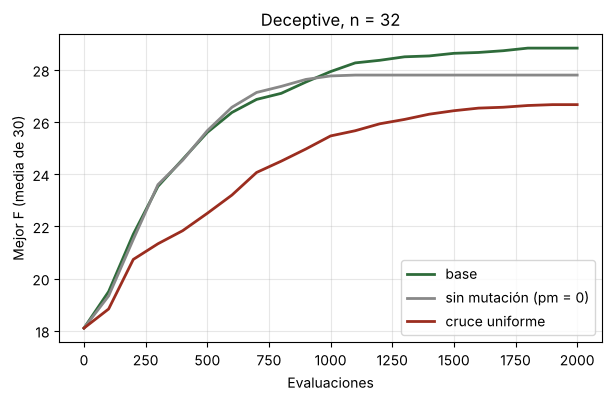

In [17]:
import matplotlib.pyplot as plt

def curva_media(cambios, semillas=SEMILLAS, paso=100):
    xs = list(range(0, 2001, paso))
    curvas = []
    for s in semillas:
        _, hist = genetico(DECEPTIVE, semilla=s, historial=True, **{**BASE, **cambios})
        curvas.append([max([m for ev, m in hist if ev <= x], default=hist[0][1]) for x in xs])
    return xs, [statistics.mean(c[i] for c in curvas) for i in range(len(xs))]

plt.figure(figsize=(7, 4))
for etiqueta, cambios, color in [("base", {}, "#2E6B3A"), ("sin mutación (pm = 0)", dict(pm=0), "#888888"),
                                 ("cruce uniforme", dict(cruce="uniforme"), "#9B2D1F")]:
    xs, ys = curva_media(cambios)
    plt.plot(xs, ys, label=etiqueta, color=color, linewidth=2)
plt.xlabel("Evaluaciones"); plt.ylabel("Mejor F (media de 30)")
plt.title("Deceptive, n = 32"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 6. Para la mochila

Lo que cambia respecto a este cuaderno:

- `aptitud` pasa a ser el valor total de la mochila, y hay que decidir qué hacer con las soluciones que superan la capacidad (penalizar o reparar). Ojo: si reparáis, reparar y evaluar cuenta como **una** evaluación.
- La medida es el gap respecto al óptimo de la instancia (2981), y solo cuentan las soluciones que caben.
- El proceso es el mismo: presupuesto fijo, hipótesis antes de ejecutar, mismas semillas, umbral de ruido, factorial donde haya dudas y validación con semillas nuevas.